# Introduction

This notebook is part of the Machine Learning lifecycle for the **Melbourne Housing Market** dataset.  
The goal of this stage is to prepare the dataset for modeling by performing:

- Data preprocessing (dropping irrelevant features, handling outliers, missing values, etc.)
- Feature engineering (encoding, scaling, transformations)
- Building reproducible **pipelines** for training and inference

We assume that data cleaning and EDA have already been completed.


In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import dtype

# ML tools
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.feature_selection import SequentialFeatureSelector

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## Load the Dataset

We load the cleaned dataset obtained after EDA.  
Ensure the file path points to the latest cleaned version of the dataset.


In [121]:
df = pd.read_csv('data/melbourne_housing_cleaned_v1.csv')
df.head()

,Suburb,Address,Rooms,Type,Method,SellerG,Date,Distance,Postcode,Bedroom,...,Landsize,BuildingArea,YearBuilt,CouncilArea,Latitude,Longtitude,Regionname,Propertycount,ParkingArea,Price
0,Northcote,303/231 St Georges Rd,2,u,S,McGrath,12/8/2017,5.3,3070.0,3.0,...,515.0,74.0,1970.0,Darebin City Council,-37.806498,144.992667,Northern Metropolitan,11364.0,Detached Garage,673000.0
1,Bentleigh East,63 Barrington St,3,h,S,Jellis,26/08/2017,13.8,3165.0,3.0,...,515.0,148.0,1960.0,Glen Eira City Council,-37.912970,145.073500,Southern Metropolitan,10969.0,Attached Garage,1372500.0
2,Reservoir,39 Crevelli St,3,h,S,Stockdale,3/9/2017,12.0,3073.0,3.0,...,170.0,128.0,1950.0,Darebin City Council,-37.729240,145.029810,Northern Metropolitan,21650.0,Outdoor Stall,612500.0
3,Jacana,53 Lorraine Cr,3,h,S,YPA,20/05/2017,14.5,3047.0,3.0,...,515.0,148.0,1960.0,Hume City Council,-37.806498,144.992667,Northern Metropolitan,851.0,Attached Garage,515000.0
4,Prahran,93 Charles St,3,h,S,Marshall,28/05/2016,4.5,3181.0,2.0,...,238.0,153.0,1890.0,Stonnington City Council,-37.847600,144.989200,Southern Metropolitan,7717.0,Carport,2180000.0


## Drop Non-Significant Columns

From the EDA stage, we identified certain columns that have little or no predictive power or contain excessive unique values. We will remove those columns to simplify the model and reduce noise.


In [122]:
cols_to_drop = ["Address","ParkingArea","Rooms","Postcode", "Date"]

df.drop(columns=cols_to_drop, inplace=True)
print(f"Dropped columns: {cols_to_drop}")

Dropped columns: ['Address', 'ParkingArea', 'Rooms', 'Postcode', 'Date']


## Handle Outliers

After reviewing the EDA results and visualizing distributions using box plots:

- The columns **`Landsize`**, **`BuildingArea`**, and **`Price`** appeared to be**highly skewed** with extreme right-side values.  
  We will apply a **log transformation** to these columns to reduce skewness and normalize their distributions.

- The columns **`Distance`**, **`Car`**, and **`Bathroom`**, though slightly skewed, do **not exhibit extreme outliers**.  
  Their value ranges (max values around 49, 7, and 7 respectively) are reasonable, so we will **retain them as-is**.

- The **`YearBuilt`** column, though skewed, naturally reflects the distribution of house construction years  
  and will also be left unchanged.

> *Note:* Because log(0) is undefined, we will add +1 to each column before applying the transformation to handle any zero values safely.



In [123]:
# Columns identified as highly skewed
skewed_cols = ['Landsize', 'BuildingArea', 'Price']

# Apply log(1 + x) transformation to reduce skewness
for col in skewed_cols:
    if col in df.columns:
        df[f'Log_{col}'] = np.log1p(df[col])  # log1p handles 0 values gracefully

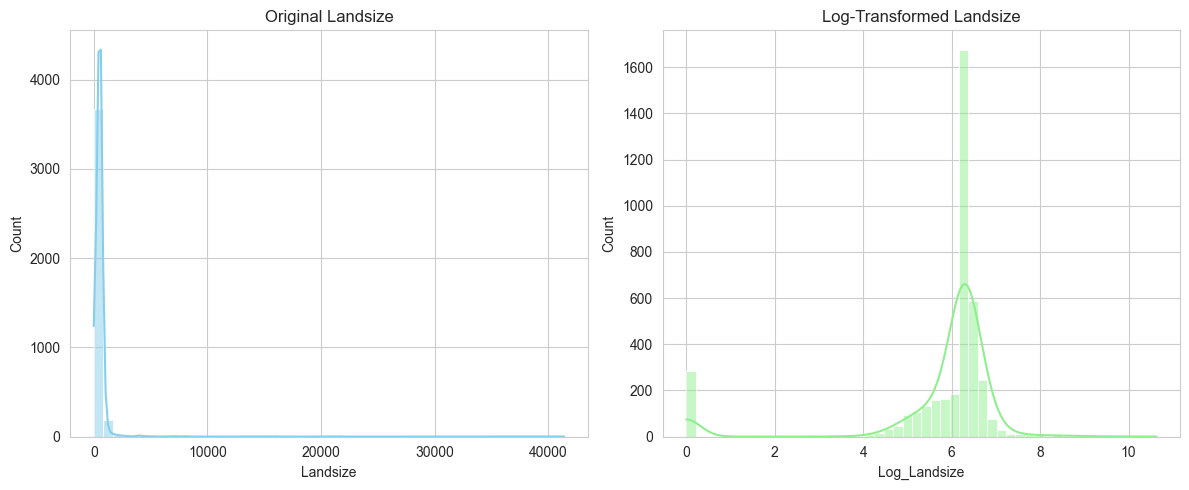

Landsize -> Skewness before: 27.88, after log-transform: -2.75



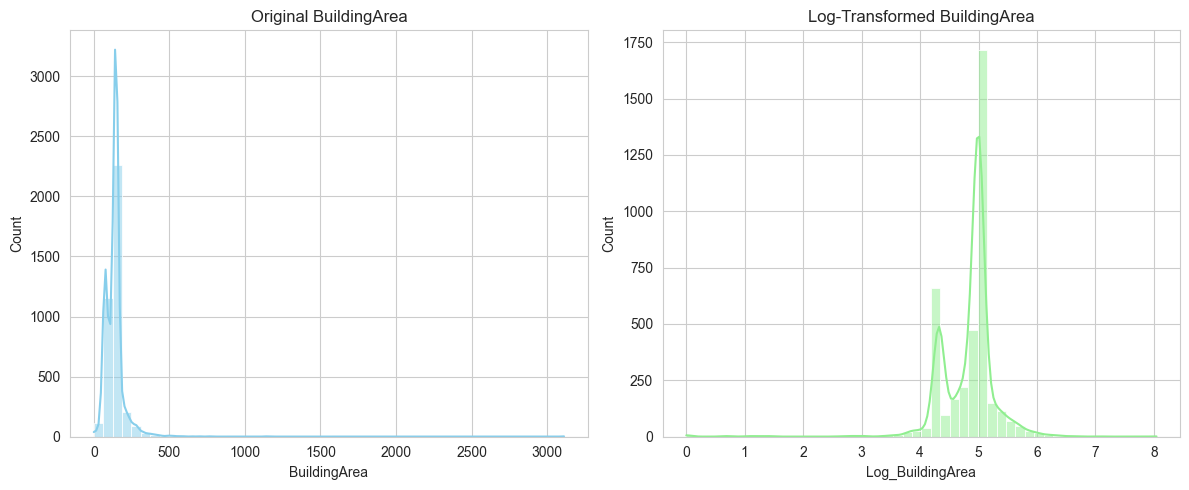

BuildingArea -> Skewness before: 16.39, after log-transform: -3.11



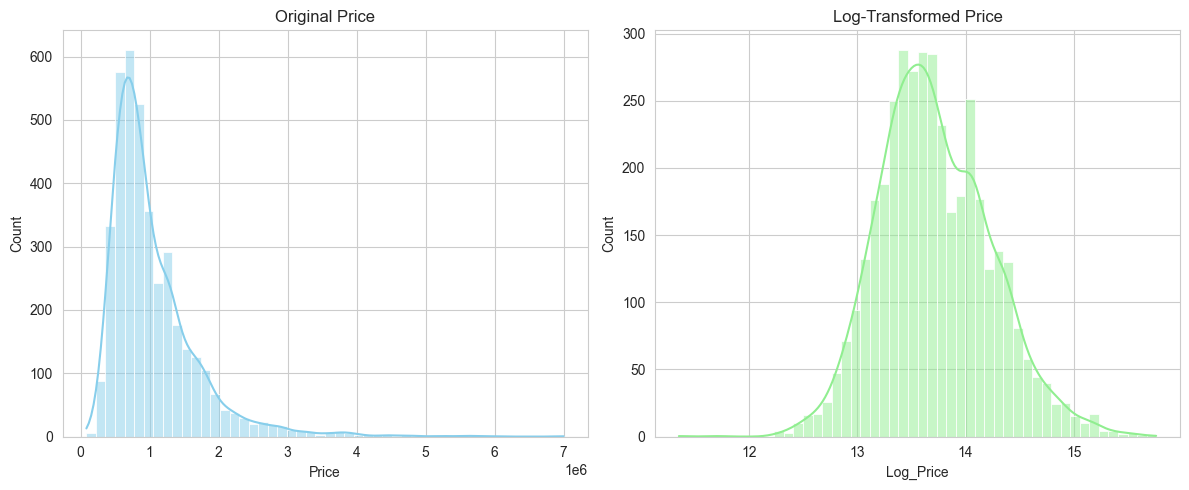

Price -> Skewness before: 2.42, after log-transform: 0.33



In [113]:
for col in skewed_cols:
    plt.figure(figsize=(12, 5))

    # Original
    plt.subplot(1, 2, 1)
    sns.histplot(df[col], bins=50, kde=True, color='skyblue')
    plt.title(f'Original {col}')
    plt.xlabel(col)

    # Log-transformed
    plt.subplot(1, 2, 2)
    sns.histplot(df[f'Log_{col}'], bins=50, kde=True, color='lightgreen')
    plt.title(f'Log-Transformed {col}')
    plt.xlabel(f'Log_{col}')

    plt.tight_layout()
    plt.show()

    # Print skewness before and after
    original_skew = df[col].skew()
    log_skew = df[f'Log_{col}'].skew()
    print(f"{col} -> Skewness before: {original_skew:.2f}, after log-transform: {log_skew:.2f}\n")

## FEATURE ENGINEERING
Feature engineering aims to enhance the dataset by transforming existing variables into more informative or model-friendly forms.  
In this stage, we perform **feature transformation**, focusing primarily on encoding categorical variables so they can be effectively used in machine learning models.

Different categorical features have different characteristics — some have only a few possible values (low cardinality), while others have hundreds (high cardinality).  
Hence, a **mixed encoding strategy** is used to handle each feature appropriately.

### 1. Feature Transformation
Different encoding strategies are used based on the **cardinality** and **semantic meaning** of each categorical variable:

| Feature | Unique | Encoding Method | Reason |
|----------|----------|----------------|--------|
| Suburb | 295 | Frequency / Target | High cardinality, location-based |
| SellerG | 195 | Frequency / Target | High cardinality, weak effect |
| Type | 3 | One-Hot | Low cardinality, categorical |
| Method | 5 | One-Hot | Low cardinality, sale type |
| CouncilArea | 32 | Frequency / Target | Medium cardinality, location |
| Regionname | 8 | One-Hot | Low cardinality, regional grouping |

This mixed encoding approach balances interpretability and efficiency, preventing excessive feature expansion while preserving meaningful relationships.

In [124]:
from sklearn.preprocessing import TargetEncoder, OneHotEncoder

encoded_df = df.copy()

# ====== 1. Frequency Encoding ======
# Suitable for high-cardinality features like Suburb and SellerG
for col in ["Suburb", "SellerG"]:
    freq_map = encoded_df[col].value_counts().to_dict()
    encoded_df[f"{col}_enc"] = encoded_df[col].map(freq_map)
    print(f"Applied frequency encoding to '{col}'")

# ====== 2. Target Encoding ======
# Used for features moderately related to Price (CouncilArea)
target_encoder = TargetEncoder(smooth="auto", target_type="continuous")
encoded_df["CouncilArea_enc"] = target_encoder.fit_transform(
    encoded_df[["CouncilArea"]], 
    encoded_df["Price"]
)
print("Applied target encoding to 'CouncilArea'")

# ====== 3. One-Hot Encoding ======
# For low-cardinality categorical features
onehot_features = ["Type", "Method", "Regionname"]
onehot_encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore')

# Fit and transform
onehot_encoded = onehot_encoder.fit_transform(encoded_df[onehot_features])

# Get feature names
feature_names = onehot_encoder.get_feature_names_out(onehot_features)

# Create DataFrame with encoded features
onehot_df = pd.DataFrame(onehot_encoded, columns=feature_names, index=encoded_df.index)

# Drop original columns and concatenate encoded ones
encoded_df = encoded_df.drop(columns=onehot_features)
encoded_df = pd.concat([encoded_df, onehot_df], axis=1)

print(f"Applied one-hot encoding to {onehot_features}")

# Drop encoded columns
encoded_df = encoded_df.drop(columns=['Suburb', 'SellerG', 'CouncilArea'])

Applied frequency encoding to 'Suburb'
Applied frequency encoding to 'SellerG'
Applied target encoding to 'CouncilArea'
Applied one-hot encoding to ['Type', 'Method', 'Regionname']


In [115]:
encoded_df.head()

,Distance,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Latitude,Longtitude,Propertycount,...,Method_SA,Method_SP,Method_VB,Regionname_Eastern Victoria,Regionname_Northern Metropolitan,Regionname_Northern Victoria,Regionname_South-Eastern Metropolitan,Regionname_Southern Metropolitan,Regionname_Western Metropolitan,Regionname_Western Victoria
0,5.3,3.0,1.0,2.0,515.0,74.0,1970.0,-37.806498,144.992667,11364.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,13.8,3.0,1.0,2.0,515.0,148.0,1960.0,-37.912970,145.073500,10969.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,12.0,3.0,1.0,1.0,170.0,128.0,1950.0,-37.729240,145.029810,21650.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,14.5,3.0,1.0,2.0,515.0,148.0,1960.0,-37.806498,144.992667,851.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,4.5,2.0,2.0,2.0,238.0,153.0,1890.0,-37.847600,144.989200,7717.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


 1. **Frequency Encoding**
   - Replaces each category with its occurrence count.
   - Retains useful information about category prevalence without inflating feature space.
   - Example: If *Suburb A* appears 300 times and *Suburb B* appears 10 times, their encoded values will be 300 and 10.

 2. **Target Encoding**
   - Replaces each category with the mean value of the target (`Price`) within that category.
   - Captures the direct relationship between categorical values and the target variable.
   - Applied carefully to avoid data leakage (ideally within cross-validation in the full pipeline).

 3. **One-Hot Encoding**
   - Expands low-cardinality categorical features into separate binary columns.
   - Keeps interpretability while maintaining model compatibility.
   - Used for `Type`, `Method`, and `Regionname`, which each have only a few possible values.


In [79]:
encoded_df.shape

(3895, 30)

### 2. Feature Creation

Feature creation involves generating new variables derived from existing ones to expose hidden patterns or improve model performance.  
For housing data, this step often includes combining, scaling, or deriving features that better reflect property characteristics and market dynamics.

In this dataset, we create new features that describe:
- **Age of the property**
- **Land and building proportions**
- **Distance-based attributes**

These engineered features help the model understand structural efficiency, property condition, and location context.


In [125]:
# Copy encoded dataset
features_df = encoded_df.copy()

# --- Property Age ---
# Convert YearBuilt to property age (as of latest date in dataset)
latest_year = features_df['YearBuilt'].max()
features_df['PropertyAge'] = latest_year - features_df['YearBuilt']

# --- Price per Square Meter (Cost Efficiency) ---
features_df['Price_Per_SqM'] = features_df['Price'] / (features_df['BuildingArea'] + 1)
features_df['Log_Price_Per_SqM'] = np.log1p(features_df['Price_Per_SqM'])
# --- House Size Indicator ---
# Combine building and land dimensions into one general property size measure
features_df["TotalArea"] = features_df["Landsize"] + features_df["BuildingArea"]
features_df['Log_TotalArea'] = np.log1p(features_df["TotalArea"]) # transform feature because Landsize and BuildingArea are highly skewed columns


**Feature: Is_CBD**

**Description:**
The Is_CBD column is a binary feature that indicates whether a property is located within 5 kilometers of Melbourne’s Central Business District (CBD).

1 → Property is within 5 km of the CBD (central area)

0 → Property is beyond 5 km from the CBD

**Rationale:**
Property prices in Melbourne are strongly influenced by proximity to the city center. Houses located closer to the CBD typically have:

Better access to jobs, transport, and amenities

Higher demand and limited land availability

Consequently, higher prices per square meter

By converting the continuous Distance variable into this binary flag, we capture the “CBD premium” — the price boost associated with being in or near the central urban zone.

**Why it’s important:**

Adds a non-linear perspective to the model that pure distance may not fully capture.

Helps the model distinguish between prime urban locations and suburban/outer areas, even if two properties are similar in size or age.

Works well alongside the continuous Distance feature to represent both the overall distance effect and the central location effect.

In [126]:
# Create is_CBD binary feature
features_df['Is_CBD'] = (features_df['Distance'] < 5).astype(int)

In [118]:
features_df.head()

,Distance,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Latitude,Longtitude,Propertycount,...,Regionname_South-Eastern Metropolitan,Regionname_Southern Metropolitan,Regionname_Western Metropolitan,Regionname_Western Victoria,PropertyAge,Price_Per_SqM,Log_Price_Per_SqM,TotalArea,Log_TotalArea,Is_CBD
0,5.3,3.0,1.0,2.0,515.0,74.0,1970.0,-37.806498,144.992667,11364.0,...,0.0,0.0,0.0,0.0,47.0,8973.333333,9.102124,589.0,6.380123,0
1,13.8,3.0,1.0,2.0,515.0,148.0,1960.0,-37.912970,145.073500,10969.0,...,0.0,1.0,0.0,0.0,57.0,9211.409396,9.128307,663.0,6.498282,0
2,12.0,3.0,1.0,1.0,170.0,128.0,1950.0,-37.729240,145.029810,21650.0,...,0.0,0.0,0.0,0.0,67.0,4748.062016,8.465702,298.0,5.700444,0
3,14.5,3.0,1.0,2.0,515.0,148.0,1960.0,-37.806498,144.992667,851.0,...,0.0,0.0,0.0,0.0,57.0,3456.375839,8.148265,663.0,6.498282,0
4,4.5,2.0,2.0,2.0,238.0,153.0,1890.0,-37.847600,144.989200,7717.0,...,0.0,1.0,0.0,0.0,127.0,14155.844156,9.557953,391.0,5.971262,1


In [127]:
cleaned_df = features_df.copy()
cleaned_df = cleaned_df.drop(columns=['BuildingArea','Landsize','TotalArea','Price_Per_SqM','Price']) # Drop transformed columns
cleaned_df.to_csv('data/melbourne_housing_cleaned_v2.csv', index=False)

## Feature Selection

After completing feature transformation and creation, the next step is to **select the most relevant features** that have strong predictive power for the target variable (`Price`).

Feature selection helps to:
- Reduce overfitting by removing irrelevant features.  
- Improve model performance and generalization.  
- Simplify the model for better interpretability.  

We will use two complementary statistical methods designed for **regression problems**:
1. **F-Test (Regr.)** — measures linear relationship strength between each feature and the target.
2. **Mutual Information (MI)** — measures both linear and non-linear dependencies between features and the target.


In [128]:
from sklearn.feature_selection import f_regression, mutual_info_regression,SelectKBest

# Make a copy
selection_df = cleaned_df.copy()

target = 'Log_Price'
X = selection_df.drop(columns=[target]) #
y = selection_df[target]

print(f"Feature matrix shape: {X.shape}")
print(f"Target variable: {target}")

Feature matrix shape: (3895, 30)
Target variable: Log_Price


### Filtering Techniques (Statistical Methods)
### 1: F-Test for Regression

The **F-test** (from ANOVA) measures how strongly each feature is linearly correlated with the target variable.  
Higher F-values indicate stronger linear relationships.

However, it only captures *linear* effects, so features with non-linear influence might be undervalued.


In [129]:
# Create selector with F-test (linear relationships)
selector_f = SelectKBest(score_func=f_regression, k=10)

# Fit selector on data
selector_f.fit(X, y)

# Get scores and p-values
f_scores = selector_f.scores_
p_values = selector_f.pvalues_

# Combine into a DataFrame
f_results = pd.DataFrame({
    'Feature': X.columns,
    'F_Score': f_scores,
    'p_Value': p_values
}).sort_values(by='F_Score', ascending=False)

print("Top 10 features by F-Test using SelectKBest:\n")
display(f_results.head(10))

Top 10 features by F-Test using SelectKBest:



,Feature,F_Score,p_Value
27,Log_Price_Per_SqM,1873.420738,0.000000e+00
12,CouncilArea_enc,1081.680752,1.488685e-209
14,Type_u,1045.838274,1.955892e-203
9,Log_BuildingArea,922.770885,4.412313e-182
1,Bedroom,920.156591,1.271152e-181
2,Bathroom,721.245767,6.694444e-146
23,Regionname_Southern Metropolitan,447.318367,4.488288e-94
28,Log_TotalArea,366.107485,4.553902e-78
26,PropertyAge,312.741215,2.232527e-67
4,YearBuilt,312.741215,2.232527e-67


### 2: Mutual Information (MI)

**Mutual Information (MI)** measures the dependency between two variables — how much knowing one variable reduces uncertainty about the other.  
Unlike the F-test, MI captures both **linear and non-linear** relationships.

A higher MI score means the feature provides more information about the target (`Price`).


In [130]:
# Create selector with MI (nonlinear relationships)
selector_mi = SelectKBest(score_func=mutual_info_regression, k=10)
selector_mi.fit(X, y)

mi_scores = selector_mi.scores_

# Combine results
mi_results = pd.DataFrame({
    'Feature': X.columns,
    'MI_Score': mi_scores
}).sort_values(by='MI_Score', ascending=False)

print("Top 10 features by Mutual Information using SelectKBest:\n")
display(mi_results.head(10))

Top 10 features by Mutual Information using SelectKBest:



,Feature,MI_Score
27,Log_Price_Per_SqM,2.677753
12,CouncilArea_enc,0.212499
9,Log_BuildingArea,0.211426
28,Log_TotalArea,0.163258
0,Distance,0.163038
4,YearBuilt,0.144436
26,PropertyAge,0.142033
5,Latitude,0.141266
7,Propertycount,0.139621
14,Type_u,0.132074


### 3: Compare F-Test and Mutual Information Results

Both methods identify strong predictors of house price, but they capture different types of relationships:

| Method | Detects | Suitable For |
|--------|----------|--------------|
| **F-Test** | Linear relationships | Linear regression models |
| **Mutual Information** | Linear + Non-linear relationships | Tree-based models (RF, XGB) |

To select features robustly, we can take the **intersection or union** of top-ranked features from both methods.


In [131]:
top_f = set(f_results.head(10)['Feature'])
top_mi = set(mi_results.head(10)['Feature'])
common_features = list(top_f.intersection(top_mi))
all_features = list(top_f.union(top_mi))

print("Common top features (F-test & MI):")
print(common_features)
print("\nAll top features (F-test & MI):")
print(all_features)

Common top features (F-test & MI):
['Type_u', 'CouncilArea_enc', 'Log_Price_Per_SqM', 'YearBuilt', 'Log_TotalArea', 'PropertyAge', 'Log_BuildingArea']

All top features (F-test & MI):
['Bedroom', 'Log_Price_Per_SqM', 'Propertycount', 'YearBuilt', 'Regionname_Southern Metropolitan', 'Bathroom', 'Log_TotalArea', 'PropertyAge', 'Log_BuildingArea', 'Type_u', 'CouncilArea_enc', 'Distance', 'Latitude']


### Wrapper Techniques

Unlike filter methods (e.g., F-Test or Mutual Information), which rank features based on individual statistics,  
**wrapper methods** evaluate subsets of features by actually training and validating a predictive model.  

They use model performance (e.g., R² for regression) as a criterion to determine which feature combinations yield the best results.

### Types of Wrapper Methods:
- **Forward Selection:** Start with no features, add one at a time if it improves performance.  
- **Backward Elimination:** Start with all features, remove one at a time if it doesn’t reduce performance significantly.  
- **Bidirectional (Stepwise):** A hybrid approach combining both.

### Explanation

1. **Train/Test Split:**  
   The data is divided into training (80%) and testing (20%) sets to avoid overfitting and enable unbiased evaluation.

2. **Estimator (Linear Regression):**  
   The wrapper method relies on a model to assess feature utility.  
   We use a simple **Linear Regression** estimator to measure how each feature subset affects predictive accuracy.

3. **Forward Selection Strategy:**  
   Starts with an empty set of features and adds one feature at a time that provides the **largest improvement in R² score**,  
   as evaluated through **5-fold cross-validation**.

4. **Selected Features:**  
   After fitting, the top 10 features that maximize the model’s R² score are retained for further training and evaluation.



In [132]:
# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Define estimator (Linear Regression for simplicity)
estimator = LinearRegression()

# Sequential Forward Feature Selection
selector = SequentialFeatureSelector(
    estimator,
    n_features_to_select=10,   # choose top 10 features
    direction='forward',       # forward selection strategy
    scoring='r2',              # performance metric
    cv=5,                      # 5-fold cross-validation
    n_jobs=-1                  # parallel computation
)

# Fit selector on training data
selector.fit_transform(X_train, y_train)

# Retrieve the selected feature names
selected_features = X_train.columns[selector.get_support()]
print("Selected features:", list(selected_features))

Selected features: ['Bedroom', 'Bathroom', 'Longtitude', 'Propertycount', 'Log_Landsize', 'Log_BuildingArea', 'Type_u', 'Regionname_Southern Metropolitan', 'Log_Price_Per_SqM', 'Log_TotalArea']


In [133]:
sfs_features = set(selected_features)
filter_features = set(common_features)
common_features_all = list(filter_features.union(sfs_features))
print("All features from filtering and wrapper: ")
print(common_features_all)

All features from filtering and wrapper: 
['Bedroom', 'Log_Price_Per_SqM', 'Log_Landsize', 'Propertycount', 'YearBuilt', 'Regionname_Southern Metropolitan', 'Bathroom', 'Log_TotalArea', 'PropertyAge', 'Log_BuildingArea', 'Longtitude', 'Type_u', 'CouncilArea_enc']


## Final Feature Selection and Justification

After applying multiple feature selection techniques — **F-test**, **Mutual Information**, and **Sequential Feature Selection (Wrapper)** —  
we compared and analyzed the top-ranked predictors to identify the most relevant and interpretable features for predicting **house prices**.

### Summary of Selection Results

| Method | Top Features Identified |
|---------|-------------------------|
| **F-Test & MI (Filter Methods)** | Bedroom, Log_Price_Per_SqM, Propertycount, YearBuilt, Regionname_Southern Metropolitan, Bathroom, Log_TotalArea, PropertyAge, Log_BuildingArea, Type_u, CouncilArea_enc, Distance, Suburb_enc, Latitude|
| **Sequential Feature Selector (Wrapper Method)** |Bedroom, Bathroom, Longtitude, Propertycount, Log_Landsize, Log_BuildingArea, Type_u, Regionname_Southern Metropolitan, Log_Price_Per_SqM, 'Log_TotalArea'|

---

### Final Selected Features (Hybrid Approach)

After analyzing both sets of results and considering **feature interpretability, relevance, and multicollinearity**,  
the following features were selected for the final model:

```python
final_features = [
    'Distance',
    'Bedroom',
    'Bathroom',
    'CouncilArea_enc',
    'Type_u',
    'Regionname_Southern Metropolitan',
    'Log_TotalArea',
    'Log_Landsize',
    'Log_BuildingArea',
    'Log_Price_Per_SqM',
    'PropertyAge'
    'Propertycount',
    'YearBuilt'
    'Is_CBD'
]

In [141]:
final_selection = selection_df.copy()
final_features = [
    'Distance',
    'Bedroom',
    'Bathroom',
    'CouncilArea_enc',
    'Type_u',
    'Regionname_Southern Metropolitan',
    'Log_TotalArea',
    'Log_Landsize',
    'Log_BuildingArea',
    'Log_Price_Per_SqM',
    'PropertyAge',
    'Propertycount',
    'YearBuilt',
    'Is_CBD'
]

for col in final_selection.columns:
    if col not in final_features:
        final_selection = final_selection.drop(columns=[col])

In [142]:
final_selection.to_csv('data/melbourne_housing_v3_featureEgnr.csv', index=False)